# EN3150 Assignment 03: SOTA Model 1, MobileNetV2 Fine-Tuning (Member 3)

**Model:** MobileNetV2 (Sandler et al., 2018), ImageNet-1k pretrained weights from `torchvision`.

**Key decisions**

- **Input resolution kept at 64x64** (no upsampling to 224x224). The edge-sensor premise of the
  assignment fixes the input at ≤ 64x64; upsampling adds no information but multiplies MACs by
  roughly (224/64)² ≈ 12x. The cost is that the final feature map is only 2x2 (MobileNetV2 has a
  total stride of 32).
- **Same 70/15/15 split and augmentation as Models A and B.** Only the normalisation differs: the
  pretrained weights expect ImageNet mean/std statistics.
- **Two-stage fine-tuning (20 epochs total):**
  1. *Head warm-up* (3 epochs): backbone frozen, only the new 43-class linear layer is trained
     (Adam, η = 1e-3). This stops large gradients from the randomly initialised head from
     destroying the pretrained features.
  2. *Full fine-tuning* (17 epochs): all layers unfrozen, Adam with a 10x smaller learning rate
     (η = 1e-4) and cosine decay. Full fine-tuning is needed because 64x64 traffic signs are far
     from ImageNet's 224x224 natural images.
- The checkpoint with the best validation accuracy is used for the test set.

## 0. Setup

In [1]:
import torch
print(torch.__version__, torch.version.cuda)

2.14.1+cu132 13.2


In [1]:
import os, json, time, copy, random
import numpy as np
import torch

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0
OUT_DIR = "outputs_member3"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 1. Data pipeline (identical split to Member 1, ImageNet normalisation)

In [2]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split
try:
    from tqdm.auto import tqdm          # progress bar (optional)
except ImportError:                     # works without tqdm installed
    def tqdm(iterable, **kwargs):
        return iterable

# ImageNet statistics, because the backbone was pretrained with them
NORM_MEAN, NORM_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
BATCH_SIZE = 64

# Same augmentations as Member 1 (no horizontal flips: they would change sign meaning)
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ColorJitter(brightness=0.2),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])
eval_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

raw_dataset = datasets.GTSRB(root="./data", split="train", download=True)


class CachedResizedDataset(Dataset):
    """Loads every GTSRB image ONCE, resizes it to 64x64 and keeps it in RAM.

    Member 1's pipeline resizes to 64x64 as its first transform, so resizing here
    gives exactly the same pixels; it just avoids re-reading ~26k files from disk
    every epoch (several training runs would otherwise be disk-bound).
    """
    def __init__(self, base):
        self.images, self.labels = [], []
        for img, label in tqdm(base, desc="Caching 64x64 images"):
            self.images.append(img.convert("RGB").resize((64, 64), resample=2))  # 2 = BILINEAR
            self.labels.append(int(label))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.images[i], self.labels[i]


cached_dataset = CachedResizedDataset(raw_dataset)

# 70/15/15 split with the SAME seed and sizes as Member 1 -> identical indices
total_size = len(cached_dataset)
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size
generator = torch.Generator().manual_seed(42)
train_subset, val_subset, test_subset = random_split(
    cached_dataset, [train_size, val_size, test_size], generator=generator
)


class SubsetWrapper(Dataset):
    """Applies a transform to a Subset (augmentation only on the training subset)."""
    def __init__(self, subset, transform=None):
        self.subset, self.transform = subset, transform

    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label

    def __len__(self):
        return len(self.subset)


train_data = SubsetWrapper(train_subset, transform=train_transforms)
val_data = SubsetWrapper(val_subset, transform=eval_transforms)
test_data = SubsetWrapper(test_subset, transform=eval_transforms)

print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")
# Cross-check these against Member 1's notebook (train_subset.indices[:10]) to confirm the split matches
print("First 10 train indices:", train_subset.indices[:10])
print("First 10 test indices: ", test_subset.indices[:10])
assert (len(train_data), len(val_data), len(test_data)) == (18648, 3996, 3996)

Train: 18648, Val: 3996, Test: 3996
First 10 train indices: [7782, 12493, 1134, 3868, 16314, 8695, 25534, 25681, 7206, 14960]
First 10 test indices:  [16146, 20109, 13872, 6038, 12506, 11852, 5339, 3771, 3204, 11921]


In [3]:
kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(train_data, shuffle=True, generator=torch.Generator().manual_seed(SEED), **kw)
val_loader = DataLoader(val_data, shuffle=False, **kw)
test_loader = DataLoader(test_data, shuffle=False, **kw)

## 2. Build MobileNetV2 with a new 43-class head

In [4]:
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

NUM_CLASSES = 43
model = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)
# Original head: Dropout(0.2) -> Linear(1280, 1000). Replace the Linear layer only.
model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)
model = model.to(device)

def count(params):
    return sum(p.numel() for p in params)

n_total = count(model.parameters())
n_backbone = count(model.features.parameters())
n_head = count(model.classifier.parameters())
print(f"Total parameters:    {n_total:,}")
print(f"  Backbone (features): {n_backbone:,}")
print(f"  New head (1280->43): {n_head:,}  (= 1280*43 + 43)")
assert n_head == 1280 * 43 + 43

# Shape check: 64x64 input -> 2x2x1280 feature map -> 43 logits
with torch.no_grad():
    dummy = torch.zeros(2, 3, 64, 64, device=device)
    print("Feature map:", tuple(model.features(dummy).shape), "| logits:", tuple(model(dummy).shape))

Total parameters:    2,278,955
  Backbone (features): 2,223,872
  New head (1280->43): 55,083  (= 1280*43 + 43)
Feature map: (2, 1280, 2, 2) | logits: (2, 43)


## 3. Two-stage fine-tuning

In [5]:
%pip install scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import torch.optim as optim
from sklearn.metrics import accuracy_score

criterion = nn.CrossEntropyLoss()
HEAD_EPOCHS, FT_EPOCHS = 3, 17          # 20 epochs in total
history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "epoch_time", "stage"]}


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return total_loss / len(labels), accuracy_score(labels, preds), preds, labels


def train_epochs(n_epochs, optimizer, scheduler=None, stage=""):
    global best_val_acc, best_state
    for _ in range(n_epochs):
        model.train()
        t0, run_loss, correct, seen = time.time(), 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            seen += x.size(0)
        if scheduler is not None:
            scheduler.step()
        if device.type == "cuda":
            torch.cuda.synchronize()
        vl, va, _, _ = evaluate(model, val_loader)
        for k, v in zip(history, [run_loss / seen, correct / seen, vl, va, time.time() - t0, stage]):
            history[k].append(v)
        if va > best_val_acc:
            best_val_acc, best_state = va, copy.deepcopy(model.state_dict())
        e = len(history["val_acc"])
        print(f"[{stage}] epoch {e:02d} | train loss {history['train_loss'][-1]:.4f} "
              f"acc {history['train_acc'][-1]:.4f} | val loss {vl:.4f} acc {va:.4f} | "
              f"{history['epoch_time'][-1]:.1f}s")


best_val_acc, best_state = -1.0, None

# ---- Stage 1: freeze the backbone, train only the new head ----
for p in model.features.parameters():
    p.requires_grad = False
opt_head = optim.Adam(model.classifier.parameters(), lr=1e-3)
print(f"Stage 1 trainable params: {count(p for p in model.parameters() if p.requires_grad):,}")
train_epochs(HEAD_EPOCHS, opt_head, stage="head")

# ---- Stage 2: unfreeze everything, fine-tune with a small learning rate ----
for p in model.features.parameters():
    p.requires_grad = True
opt_ft = optim.Adam(model.parameters(), lr=1e-4)
sched = optim.lr_scheduler.CosineAnnealingLR(opt_ft, T_max=FT_EPOCHS)
print(f"Stage 2 trainable params: {count(p for p in model.parameters() if p.requires_grad):,}")
train_epochs(FT_EPOCHS, opt_ft, sched, stage="full")

model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_val_acc:.4f}")
with open(f"{OUT_DIR}/mobilenetv2_history.json", "w") as f:
    json.dump(history, f)

Stage 1 trainable params: 55,083
[head] epoch 01 | train loss 1.9544 acc 0.4422 | val loss 1.5825 acc 0.5475 | 27.0s
[head] epoch 02 | train loss 1.4275 acc 0.5634 | val loss 1.4429 acc 0.5681 | 25.6s
[head] epoch 03 | train loss 1.3114 acc 0.5879 | val loss 1.2855 acc 0.6204 | 25.5s
Stage 2 trainable params: 2,278,955
[full] epoch 04 | train loss 0.5711 acc 0.8181 | val loss 0.1965 acc 0.9359 | 34.7s
[full] epoch 05 | train loss 0.1566 acc 0.9514 | val loss 0.0614 acc 0.9835 | 34.8s
[full] epoch 06 | train loss 0.0681 acc 0.9803 | val loss 0.0369 acc 0.9887 | 35.0s
[full] epoch 07 | train loss 0.0408 acc 0.9880 | val loss 0.0286 acc 0.9920 | 35.0s
[full] epoch 08 | train loss 0.0260 acc 0.9931 | val loss 0.0179 acc 0.9957 | 34.7s
[full] epoch 09 | train loss 0.0176 acc 0.9953 | val loss 0.0114 acc 0.9972 | 34.6s
[full] epoch 10 | train loss 0.0135 acc 0.9960 | val loss 0.0138 acc 0.9960 | 34.6s
[full] epoch 11 | train loss 0.0109 acc 0.9974 | val loss 0.0148 acc 0.9962 | 35.2s
[full] 

## 4. Loss and accuracy curves

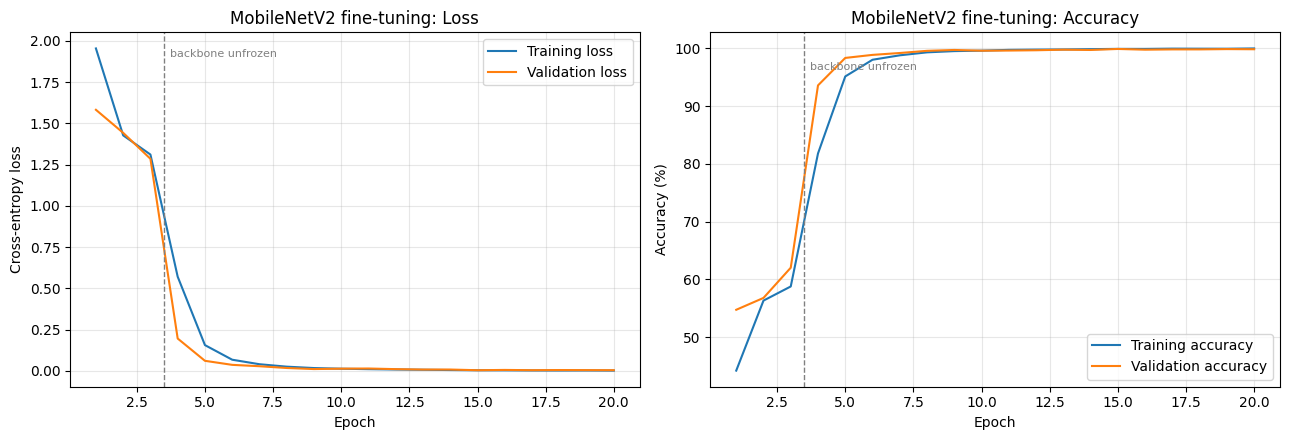

In [7]:
import matplotlib.pyplot as plt

ep = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ep, history["train_loss"], label="Training loss")
axes[0].plot(ep, history["val_loss"], label="Validation loss")
axes[1].plot(ep, np.array(history["train_acc"]) * 100, label="Training accuracy")
axes[1].plot(ep, np.array(history["val_acc"]) * 100, label="Validation accuracy")
for ax, t, yl in zip(axes, ["Loss", "Accuracy"], ["Cross-entropy loss", "Accuracy (%)"]):
    ax.axvline(HEAD_EPOCHS + 0.5, color="gray", ls="--", lw=1)
    ax.text(HEAD_EPOCHS + 0.7, ax.get_ylim()[1] * 0.95, "backbone unfrozen", color="gray", fontsize=8, va="top")
    ax.set_title(f"MobileNetV2 fine-tuning: {t}"); ax.set_xlabel("Epoch"); ax.set_ylabel(yl)
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/mobilenetv2_curves.png", dpi=200); plt.show()

## 5. Test-set evaluation

{
  "accuracy": 0.998998998998999,
  "precision_macro": 0.9981088912149759,
  "recall_macro": 0.9985129313104688,
  "f1_macro": 0.9982834838648755,
  "precision_weighted": 0.9990227768538271,
  "recall_weighted": 0.998998998998999
}
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        19
           1      1.000     1.000     1.000       223
           2      1.000     1.000     1.000       233
           3      1.000     1.000     1.000       148
           4      1.000     0.991     0.995       221
           5      1.000     1.000     1.000       209
           6      1.000     1.000     1.000        47
           7      1.000     1.000     1.000       155
           8      0.986     1.000     0.993       144
           9      1.000     1.000     1.000       155
          10      1.000     1.000     1.000       197
          11      1.000     1.000     1.000       139
          12      1.000     1.000     1.000       213
          

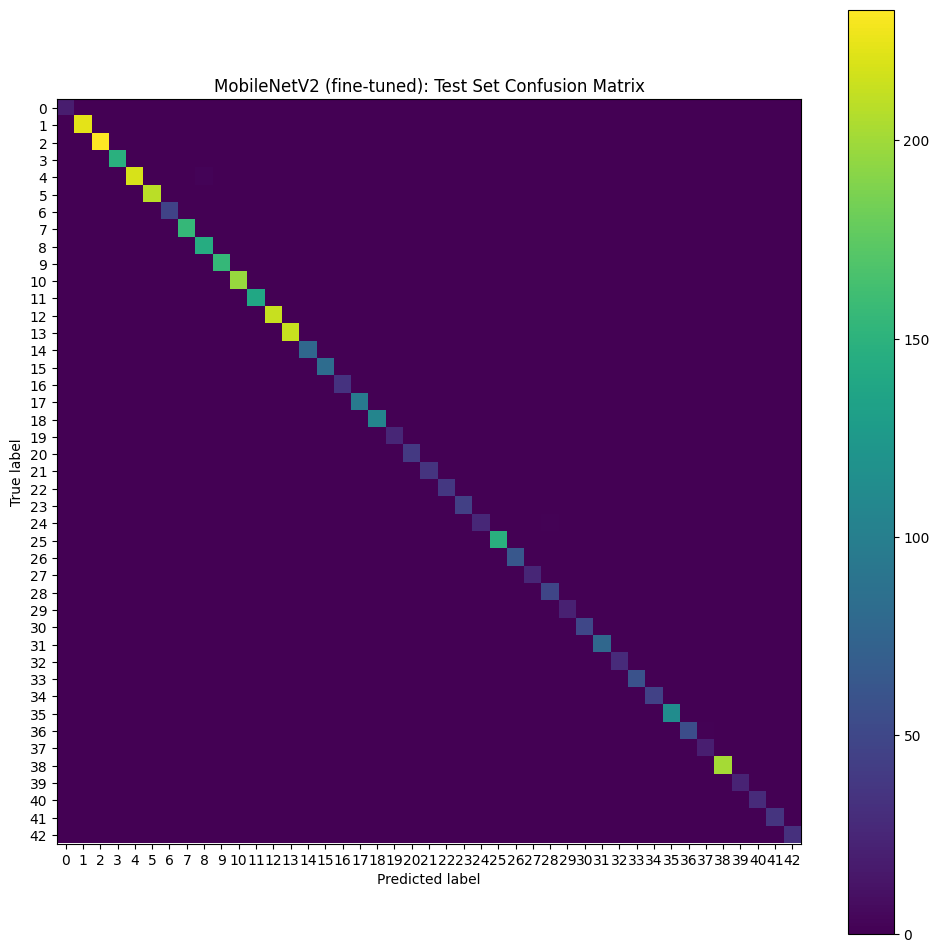

Most frequent confusions (true -> predicted : count):
   4 ->  8 : 2
  24 -> 28 : 1
  36 -> 37 : 1


In [8]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)

test_loss, test_acc, preds, labels = evaluate(model, test_loader)
test_metrics = {
    "accuracy": test_acc,
    "precision_macro": precision_score(labels, preds, average="macro", zero_division=0),
    "recall_macro": recall_score(labels, preds, average="macro", zero_division=0),
    "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    "precision_weighted": precision_score(labels, preds, average="weighted", zero_division=0),
    "recall_weighted": recall_score(labels, preds, average="weighted", zero_division=0),
}
print(json.dumps(test_metrics, indent=2))
print(classification_report(labels, preds, digits=3, zero_division=0))

# Same style as Member 1's Model A confusion matrix so the figures are comparable
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="viridis", include_values=False)
plt.title("MobileNetV2 (fine-tuned): Test Set Confusion Matrix")
plt.savefig(f"{OUT_DIR}/mobilenetv2_confusion_matrix.png", dpi=200); plt.show()

# Most confused class pairs (useful for the discussion)
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
print("Most frequent confusions (true -> predicted : count):")
for t, p in top:
    if off[t, p] > 0:
        print(f"  {t:2d} -> {p:2d} : {off[t, p]}")

## 6. Parameter count, model size on disk, quick CPU latency
Member 4 does the official MACs/latency profiling for all four models; the numbers here are for Section 5. The weights file is shared with Member 4.

In [9]:
WEIGHTS_PATH = f"{OUT_DIR}/sota1_mobilenetv2_weights.pth"
torch.save(model.state_dict(), WEIGHTS_PATH)
size_mb = os.path.getsize(WEIGHTS_PATH) / (1024 ** 2)

# Quick single-image CPU latency (warm-up + average of 100 runs)
cpu_model = copy.deepcopy(model).cpu().eval()
x1 = torch.zeros(1, 3, 64, 64)
with torch.inference_mode():
    for _ in range(10):
        cpu_model(x1)
    t0 = time.perf_counter()
    for _ in range(100):
        cpu_model(x1)
latency_ms = (time.perf_counter() - t0) / 100 * 1000

summary = {
    "model": "MobileNetV2 (ImageNet pretrained, fine-tuned)",
    "input": "3x64x64",
    "total_params": n_total,
    "trainable_params": count(p for p in model.parameters() if p.requires_grad),
    "size_on_disk_MB": round(size_mb, 2),
    "fp32_weights_MB_theoretical": round(n_total * 4 / 1024 ** 2, 2),
    "cpu_latency_ms_per_image": round(latency_ms, 2),
    "mean_epoch_time_s_head_stage": round(float(np.mean(history["epoch_time"][:HEAD_EPOCHS])), 1),
    "mean_epoch_time_s_full_stage": round(float(np.mean(history["epoch_time"][HEAD_EPOCHS:])), 1),
    "best_val_acc": best_val_acc,
    "test": test_metrics,
}
with open(f"{OUT_DIR}/sota1_mobilenetv2_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "model": "MobileNetV2 (ImageNet pretrained, fine-tuned)",
  "input": "3x64x64",
  "total_params": 2278955,
  "trainable_params": 2278955,
  "size_on_disk_MB": 8.93,
  "fp32_weights_MB_theoretical": 8.69,
  "cpu_latency_ms_per_image": 26.84,
  "mean_epoch_time_s_head_stage": 26.0,
  "mean_epoch_time_s_full_stage": 34.8,
  "best_val_acc": 0.998998998998999,
  "test": {
    "accuracy": 0.998998998998999,
    "precision_macro": 0.9981088912149759,
    "recall_macro": 0.9985129313104688,
    "f1_macro": 0.9982834838648755,
    "precision_weighted": 0.9990227768538271,
    "recall_weighted": 0.998998998998999
  }
}
